# 01. EDA — WEBSPAM-UK2007 호스트 그래프

보고서 Data section의 통계·그림 근거 (GUIDE 8절).

1. 데이터 통계표
2. degree 분포, dead end, 연결 성분
3. SET1 spam / nonspam의 degree 비교
4. TrustRank 가정 검증: 라벨 host 사이 링크 집계
5. 도메인별 host 수와 SET1 spam 비율 → **B에게 전달 (PPR seed 규모)**
6. seed 도메인에서 도달 가능한 host 비율 (PPR 점수가 0이 될 규모)

- 실행 전에 `python scripts/build_processed.py`로 `data/processed/`를 만든다.
- **SET2 라벨은 개수 집계(1번)에만 쓴다.** 나머지 분석은 SET1 라벨만 사용한다.
- 그림은 `results/figures/`에 PNG로 저장한다.

In [11]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                       # notebooks/에서 실행해도 src를 import

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from matplotlib import font_manager
from scipy.sparse.csgraph import connected_components

from src.common.schema import NONSPAM, SPAM
from src.config import load_config
from src.data import load_dataset
from src.graph import domain_of

cfg = load_config()
ds = load_dataset(cfg.path("processed_dir"))
meta = json.loads((cfg.path("processed_dir") / "meta.json").read_text(encoding="utf-8"))
FIG_DIR = cfg.path("figures_dir")
FIG_DIR.mkdir(parents=True, exist_ok=True)

A = ds.graph.adjacency
n = ds.graph.n
B = sp.csr_matrix(A > 0, dtype=np.int8)                 # 이진 그래프: degree는 링크 수가 아니라 host 수로 센다
out_deg = np.diff(B.indptr)
in_deg = np.bincount(B.indices, minlength=n)

# SET1 라벨 host (spam·nonspam). SET2는 쓰지 않는다.
s1 = np.flatnonzero((ds.in_set == 1) & np.isin(ds.labels, (SPAM, NONSPAM)))
s1_spam = ds.labels[s1] == SPAM
print(f"N = {n:,}, SET1 라벨 host = {len(s1):,} (spam {s1_spam.sum()}, nonspam {(~s1_spam).sum()})")

N = 114,529, SET1 라벨 host = 3,998 (spam 222, nonspam 3776)


In [12]:
# 그림 공통 스타일: 한글 글꼴, 얇은 표식, 옅은 격자
_kfonts = [f for f in ("Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR")
           if any(f == x.name for x in font_manager.fontManager.ttflist)]
plt.rcParams.update({
    "font.family": _kfonts + ["DejaVu Sans"],
    "axes.unicode_minus": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False,
})
NONSPAM_C, SPAM_C = "#2a78d6", "#eb6834"            # 범주 색 1·2번 (색약 구분 검증된 조합)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print(f"저장: {(FIG_DIR / f'{name}.png').relative_to(ROOT)}")

## 1. 데이터 통계표

`build_processed.py`가 기록한 `meta.json` 기준 (GUIDE 3.5절 점검표).

In [13]:
g = meta["graph"]
stats = pd.DataFrame([
    ("호스트 수 N", g["n"]),
    ("edge 수 (self-loop 제거 후)", g["nnz"]),
    ("self-loop / 중복 edge", f'{g["self_loops"]} / {g["duplicates"]}'),
    ("dead end (나가는 링크 0)", f'{g["dead_ends"]:,} ({g["dead_ends"] / g["n"]:.1%})'),
    ("들어오는 링크 0", g["in_degree_zero"]),
    ("고립 호스트", g["isolated"]),
    ("weight (링크 수) 최소 · 중앙 · 최대", f'{g["weight_min"]:.0f} · {g["weight_median"]:.0f} · {g["weight_max"]:,.0f}'),
    ("평균 out-degree", f'{g["nnz"] / g["n"]:.1f}'),
], columns=["항목", "값"])
display(stats)

lab = pd.DataFrame({s: meta["labels"][s] for s in ("SET1", "SET2")})
lab.loc["합계"] = lab.sum()
display(lab)

split = pd.DataFrame({k: meta["split"][k] for k in ("train", "val", "test")}).T
split["합계"] = split.sum(axis=1)
print(f'분할: {meta["split"]["unit"]} 단위, val_frac {meta["split"]["val_frac"]}, seed {meta["split"]["random_seed"]}')
display(split)

,항목,값
0,호스트 수 N,114529
1,edge 수 (self-loop 제거 후),1836441
2,self-loop / 중복 edge,0 / 0
3,dead end (나가는 링크 0),"49,379 (43.1%)"
4,들어오는 링크 0,4766
5,고립 호스트,3380
6,weight (링크 수) 최소 · 중앙 · 최대,"1 · 1 · 2,579,857"
7,평균 out-degree,16.0


,SET1,SET2
spam,222,122
nonspam,3776,1933
undecided,277,149
합계,4275,2204


분할: site 단위, val_frac 0.3, seed 42


,spam,nonspam,합계
train,155,2643,2798
val,67,1133,1200
test,122,1933,2055


## 2. degree 분포, dead end, 연결 성분

in-degree = 그 host로 링크를 거는 host 수, out-degree = 그 host가 링크를 거는 host 수 (이진 그래프 기준).
degree가 k인 host 수를 log-log로 그린다 (degree 0은 log 축에 그릴 수 없어 따로 표기).

저장: results\figures\degree_distribution.png


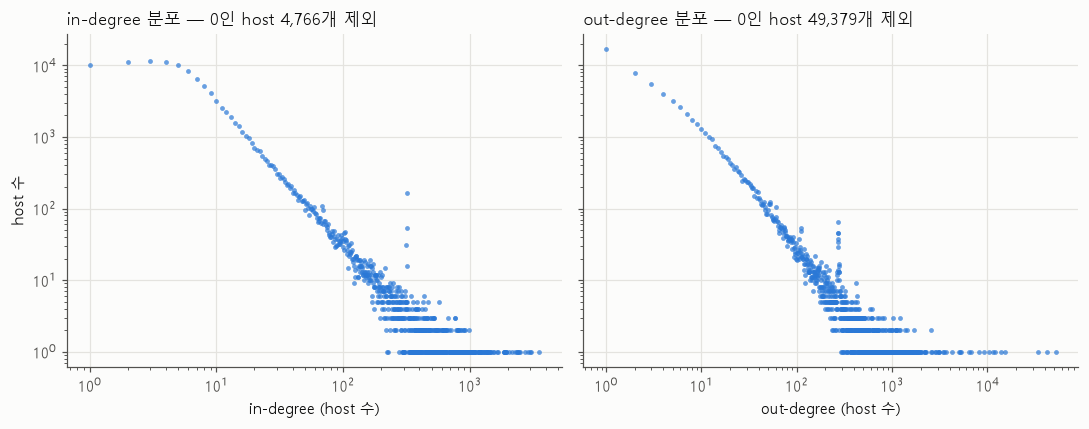

in-degree  최대 3,518 (news.bbc.co.uk), 중앙 5
out-degree 최대 51,692 (directory.thatsbritain.co.uk), 중앙 1
dead end 49,379개 (43.1%)


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, deg, name in zip(axes, (in_deg, out_deg), ("in-degree", "out-degree")):
    k, cnt = np.unique(deg[deg > 0], return_counts=True)
    ax.scatter(k, cnt, s=10, color=NONSPAM_C, alpha=0.7, linewidths=0)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"{name} (host 수)")
    ax.set_title(f"{name} 분포 — 0인 host {np.sum(deg == 0):,}개 제외", fontsize=11, loc="left")
axes[0].set_ylabel("host 수")
fig.tight_layout()
save(fig, "degree_distribution")
plt.show()

print(f"in-degree  최대 {in_deg.max():,} ({ds.graph.hostnames[in_deg.argmax()]}), 중앙 {np.median(in_deg):.0f}")
print(f"out-degree 최대 {out_deg.max():,} ({ds.graph.hostnames[out_deg.argmax()]}), 중앙 {np.median(out_deg):.0f}")
print(f"dead end {np.sum(out_deg == 0):,}개 ({np.mean(out_deg == 0):.1%})")

In [15]:
# 연결 성분: weakly(방향 무시) / strongly(방향 고려)
n_wcc, wcc = connected_components(B, directed=True, connection="weak")
n_scc, scc = connected_components(B, directed=True, connection="strong")
wcc_size, scc_size = np.bincount(wcc), np.bincount(scc)
display(pd.DataFrame({
    "성분 수": [n_wcc, n_scc],
    "최대 성분 크기": [wcc_size.max(), scc_size.max()],
    "최대 성분 비율": [f"{wcc_size.max() / n:.1%}", f"{scc_size.max() / n:.1%}"],
    "크기 1인 성분": [int((wcc_size == 1).sum()), int((scc_size == 1).sum())],
}, index=["weakly connected", "strongly connected"]))

,성분 수,최대 성분 크기,최대 성분 비율,크기 1인 성분
weakly connected,3404,111083,97.0%,3380
strongly connected,54822,59160,51.7%,54384


## 3. SET1 spam / nonspam의 degree 비교

SET1 라벨 host만 사용. 누적분포(ECDF)로 비교한다 — 선이 왼쪽에 있을수록 degree가 작은 host가 많다.
log 축에 degree 0을 함께 그리려고 x축은 degree + 1로 둔다.

저장: results\figures\degree_spam_vs_nonspam.png


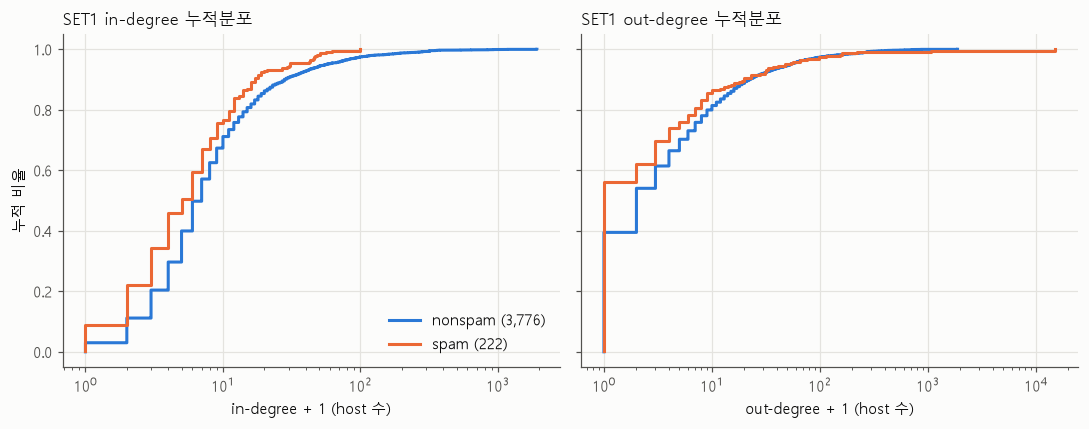

,degree,라벨,중앙값,평균,0인 비율
0,in-degree,nonspam,6.0,16.844280,3.0%
1,in-degree,spam,4.0,7.783784,9.0%
2,out-degree,nonspam,1.0,13.275953,39.5%
3,out-degree,spam,0.0,80.774775,56.3%


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, deg, name in zip(axes, (in_deg, out_deg), ("in-degree", "out-degree")):
    for is_spam, label, color in ((False, "nonspam", NONSPAM_C), (True, "spam", SPAM_C)):
        x = np.sort(deg[s1][s1_spam == is_spam]) + 1
        y = np.arange(1, len(x) + 1) / len(x)
        ax.step(x, y, where="post", color=color, label=f"{label} ({len(x):,})")
    ax.set_xscale("log")
    ax.set_xlabel(f"{name} + 1 (host 수)")
    ax.set_title(f"SET1 {name} 누적분포", fontsize=11, loc="left")
axes[0].set_ylabel("누적 비율")
axes[0].legend(loc="lower right")
fig.tight_layout()
save(fig, "degree_spam_vs_nonspam")
plt.show()

rows = []
for name, deg in (("in-degree", in_deg), ("out-degree", out_deg)):
    for is_spam, label in ((False, "nonspam"), (True, "spam")):
        d = deg[s1][s1_spam == is_spam]
        rows.append((name, label, np.median(d), d.mean(), f"{np.mean(d == 0):.1%}"))
display(pd.DataFrame(rows, columns=["degree", "라벨", "중앙값", "평균", "0인 비율"]))

## 4. TrustRank 가정 검증

TrustRank는 "좋은(nonspam) host는 spam host로 링크를 거의 걸지 않는다"는 가정에 기대어 신뢰 점수를 퍼뜨린다.
SET1 라벨 host 사이의 링크(이진)를 출발 → 도착 라벨로 집계한다.

In [17]:
mask = np.zeros(n, dtype=bool); mask[s1] = True
C = B.tocoo()
keep = mask[C.row] & mask[C.col]
src = np.where(ds.labels[C.row[keep]] == SPAM, "spam", "nonspam")
dst = np.where(ds.labels[C.col[keep]] == SPAM, "spam", "nonspam")
edge_mix = pd.crosstab(pd.Series(src, name="출발"), pd.Series(dst, name="도착"))
display(edge_mix)
display((edge_mix.div(edge_mix.sum(axis=1), axis=0) * 100).round(1).astype(str) + "%")
print(f"참고: SET1 라벨 host 중 spam 비율 {s1_spam.mean():.1%}")

도착,nonspam,spam
출발,,
nonspam,1721,45
spam,588,23


도착,nonspam,spam
출발,,
nonspam,97.5%,2.5%
spam,96.2%,3.8%


참고: SET1 라벨 host 중 spam 비율 5.6%


## 5. 도메인별 host 수와 SET1 spam 비율

`domain_of` 기준 (.uk 2단계 도메인). **PPR seed 규모를 정하는 표 → B에게 전달.**

In [18]:
dom = np.array([domain_of(h) for h in ds.graph.hostnames])
by_dom = pd.DataFrame({"host 수": pd.Series(dom).value_counts()})
s1_dom = pd.DataFrame({"domain": dom[s1], "spam": s1_spam}).groupby("domain")["spam"]
by_dom["SET1 라벨"] = s1_dom.size()
by_dom["SET1 spam"] = s1_dom.sum()
by_dom = by_dom.fillna(0).astype(int)
by_dom["SET1 spam 비율"] = (by_dom["SET1 spam"] / by_dom["SET1 라벨"].replace(0, np.nan)).map(
    lambda v: "-" if pd.isna(v) else f"{v:.1%}")
display(by_dom)

,host 수,SET1 라벨,SET1 spam,SET1 spam 비율
co.uk,89953,3117,201,6.4%
org.uk,15141,547,20,3.7%
ac.uk,5063,165,0,0.0%
gov.uk,1708,75,0,0.0%
sch.uk,1658,57,0,0.0%
nhs.uk,339,15,0,0.0%
ltd.uk,257,6,0,0.0%
me.uk,216,8,1,12.5%
police.uk,57,0,0,-
mod.uk,52,2,0,0.0%


저장: results\figures\spam_rate_by_domain.png


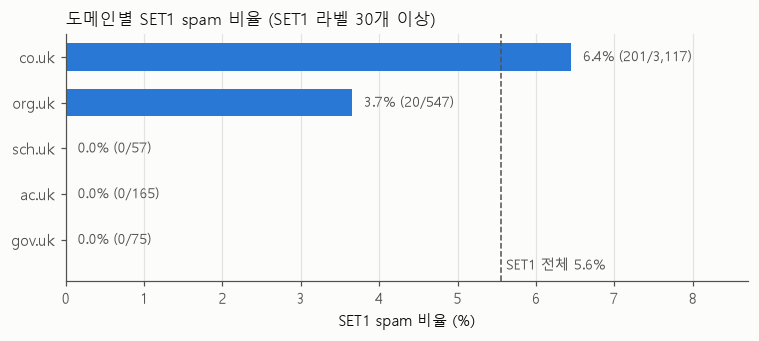

In [19]:
MIN_LABELED = 30                                    # 라벨이 너무 적은 도메인은 비율이 흔들려 그림에서 뺀다
plot = by_dom[by_dom["SET1 라벨"] >= MIN_LABELED].copy()
plot["rate"] = plot["SET1 spam"] / plot["SET1 라벨"]
plot = plot.sort_values("rate")

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh(plot.index, plot["rate"] * 100, color=NONSPAM_C, height=0.6)
overall = s1_spam.mean() * 100
ax.axvline(overall, color="#52514e", linewidth=1, linestyle="--")
ax.text(overall, -0.55, f" SET1 전체 {overall:.1f}%", color="#52514e", fontsize=9, va="center")
for bar, (_, r) in zip(bars, plot.iterrows()):
    ax.text(bar.get_width() + 0.15, bar.get_y() + bar.get_height() / 2,
            f'{r["rate"]:.1%} ({r["SET1 spam"]:,}/{r["SET1 라벨"]:,})', va="center", fontsize=9, color="#52514e")
ax.set_xlabel("SET1 spam 비율 (%)")
ax.set_title(f"도메인별 SET1 spam 비율 (SET1 라벨 {MIN_LABELED}개 이상)", fontsize=11, loc="left")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(plot["rate"].max() * 100, overall) * 1.35)
ax.set_ylim(-0.9, len(plot) - 0.5)                  # 아래쪽에 전체 비율 라벨 자리
fig.tight_layout()
save(fig, "spam_rate_by_domain")
plt.show()

## 6. seed 도메인에서 도달 가능한 host 비율

PPR·TrustRank(`dangling="teleport"`)에서 seed에서 링크를 따라 도달할 수 없는 host는 점수가 **정확히 0**이 된다.
seed 도메인(`configs/default.yaml`의 `domains.ppr_seed_domains`)에서 너비 우선 탐색으로 도달 범위를 센다.

In [20]:
def reachable(seeds):
    """seeds에서 링크 방향을 따라 도달 가능한 host (bool, 길이 N)."""
    reached = np.zeros(n, dtype=bool)
    reached[seeds] = True
    frontier = np.asarray(seeds)
    while frontier.size:
        nb = np.unique(B[frontier].indices)
        frontier = nb[~reached[nb]]
        reached[frontier] = True
    return reached


seed_domains = cfg.require("domains", "ppr_seed_domains")
rows = []
for doms in [[d] for d in seed_domains] + [seed_domains]:
    seeds = np.flatnonzero(np.isin(dom, doms))
    r = reachable(seeds)
    rows.append((" + ".join(doms), len(seeds), int(r.sum()), f"{r.mean():.1%}", int((~r).sum()),
                 f"{r[s1][~s1_spam].mean():.1%}", f"{r[s1][s1_spam].mean():.1%}"))
display(pd.DataFrame(rows, columns=["seed 도메인", "seed 수", "도달 host", "도달 비율", "점수 0 (도달 불가)",
                                    "SET1 nonspam 도달", "SET1 spam 도달"]))

,seed 도메인,seed 수,도달 host,도달 비율,점수 0 (도달 불가),SET1 nonspam 도달,SET1 spam 도달
0,ac.uk,5063,109609,95.7%,4920,96.8%,90.1%
1,gov.uk,1708,109569,95.7%,4960,96.7%,90.1%
2,ac.uk + gov.uk,6771,109612,95.7%,4917,96.8%,90.1%


## 정리

(아래 수치는 2026-11-21 실행 결과. `build_processed.py`를 다시 실행해 데이터가 바뀌면 함께 갱신한다.)

- **그래프 구조**: N = 114,529, edge 1,836,441. dead end가 43.1%로 많아 dead end 처리(`dangling`)가 결과에 영향을 줄 수 있다. weakly connected 최대 성분이 97.0%로 그래프는 사실상 하나로 이어져 있다.
- **degree**: in/out-degree 모두 소수 host에 몰린 heavy-tail 분포 (in-degree 최대 `news.bbc.co.uk` 3,518).
- **spam vs nonspam (SET1)**: spam은 in-degree가 낮고(중앙값 4 vs 6), 56.3%가 나가는 링크가 없다 (nonspam 39.5%). 반면 out-degree 평균은 spam 80.8 vs nonspam 13.3으로, 링크를 매우 많이 거는 spam이 일부 있다.
- **TrustRank 가정**: nonspam이 거는 링크의 97.5%가 nonspam으로 간다 → "좋은 host는 spam에 거의 링크하지 않는다"는 가정과 맞다. 다만 spam이 거는 링크도 96%가 nonspam으로 가므로, spam끼리 뭉치는 경향은 라벨 host 안에서는 뚜렷하지 않다.
- **도메인 (→ B)**: `ac.uk` 5,063개, `gov.uk` 1,708개. 두 도메인의 SET1 라벨 host에는 spam이 0개 → seed 후보로 적절하다. spam은 `co.uk`(6.4%)에 몰려 있다.
- **도달 범위**: `ac.uk + gov.uk` seed에서 전체의 95.7%에 도달 → PPR 점수가 0인 host는 약 4.3%. SET1 spam은 90.1%, nonspam은 96.8%가 도달 가능하다.